# Tugas - Medical Cost Prediction

|          Nama          |    NRP     |
|------------------------|------------|
| Muhammad Fardan Hafidz | 5054251021 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set style visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 10

In [2]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.

data_path = 'insurance.csv' if os.path.exists('insurance.csv') else '5. Tugas_Regression/insurance.csv'
df = pd.read_csv(data_path)

In [3]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
# Periksa missing value.
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [6]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in df.select_dtypes(include=['object']).columns:
    print(f"=== {col} ===")
    print(df[col].value_counts())
    print()

=== sex ===
sex
male      676
female    662
Name: count, dtype: int64

=== smoker ===
smoker
no     1064
yes     274
Name: count, dtype: int64

=== region ===
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.

C:\Users\muhfa\AppData\Local\Temp\ipykernel_23012\2199738272.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='smoker', y='charges', palette=['#10b981', '#ef4444'], ax=axes[1])


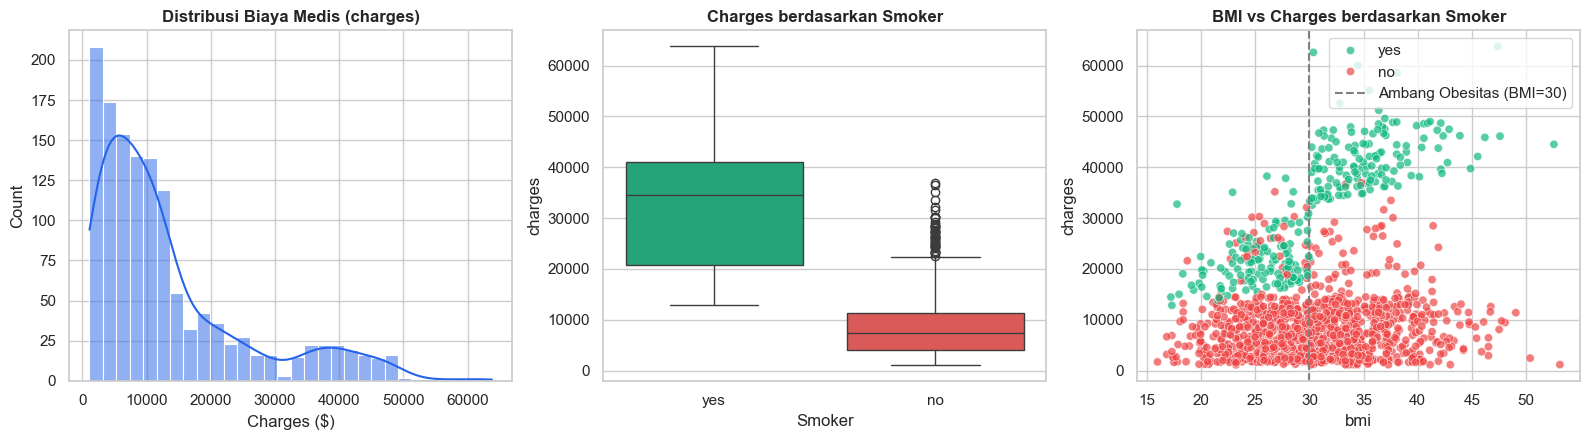

In [8]:
# EDA Sederhana: Distribusi target dan hubungan fitur kunci terhadap charges
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Distribusi charges
sns.histplot(df['charges'], kde=True, color='#2563eb', ax=axes[0])
axes[0].set_title('Distribusi Biaya Medis (charges)', fontweight='bold')
axes[0].set_xlabel('Charges ($)')

# 2. Pengaruh status perokok
sns.boxplot(data=df, x='smoker', y='charges', palette=['#10b981', '#ef4444'], ax=axes[1])
axes[1].set_title('Charges berdasarkan Smoker', fontweight='bold')
axes[1].set_xlabel('Smoker')

# 3. Hubungan BMI vs Charges berdasarkan Smoker
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette=['#10b981', '#ef4444'], alpha=0.7, ax=axes[2])
axes[2].axvline(30, color='gray', linestyle='--', label='Ambang Obesitas (BMI=30)')
axes[2].set_title('BMI vs Charges berdasarkan Smoker', fontweight='bold')
axes[2].legend()

plt.tight_layout()
plt.show()

# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.

In [9]:
# Pisahkan fitur (X) dan target (y).
X = df.drop(columns=['charges'])
y = df['charges']

print("Dimensi fitur (X) :", X.shape)
print("Dimensi target (y):", y.shape)

Dimensi fitur (X) : (1338, 6)
Dimensi target (y): (1338,)


In [10]:
# Identifikasi kolom numerik dan kategorikal.
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"Fitur numerik    : {num_cols}")
print(f"Fitur kategorikal: {cat_cols}")

Fitur numerik    : ['age', 'bmi', 'children']
Fitur kategorikal: ['sex', 'smoker', 'region']


In [11]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Jumlah sampel data latih (train): {X_train.shape[0]}")
print(f"Jumlah sampel data uji (test)  : {X_test.shape[0]}")

Jumlah sampel data latih (train): 1070
Jumlah sampel data uji (test)  : 268


In [12]:
# Buat preprocessing untuk fitur numerik dan kategorikal.

# Preprocessor dengan StandardScaler (untuk Linear, Polynomial, Ridge, Lasso, dan SVR)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Preprocessor tanpa scaling numerik (khusus untuk Decision Tree Regressor)
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Transformasi train dan test set
X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_test_scaled = preprocessor_scaled.transform(X_test)

X_train_unscaled = preprocessor_unscaled.fit_transform(X_train)
X_test_unscaled = preprocessor_unscaled.transform(X_test)

feature_names = preprocessor_scaled.get_feature_names_out()
print("Fitur setelah encoding:", list(feature_names))

Fitur setelah encoding: ['num__age', 'num__bmi', 'num__children', 'cat__sex_male', 'cat__smoker_yes', 'cat__region_northwest', 'cat__region_southeast', 'cat__region_southwest']


# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.

In [13]:
# Inisialisasi dan latih Linear Regression.
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

print(f"Intercept: {lr_model.intercept_:.4f}")
print("Koefisien:")
for feat, coef in zip(feature_names, lr_model.coef_):
    print(f"  {feat:30s}: {coef:10.4f}")

Intercept: 8955.2448
Koefisien:
  num__age                      :  3614.9754
  num__bmi                      :  2036.2281
  num__children                 :   516.8902
  cat__sex_male                 :   -18.5917
  cat__smoker_yes               : 23651.1289
  cat__region_northwest         :  -370.6773
  cat__region_southeast         :  -657.8643
  cat__region_southwest         :  -809.7994


In [14]:
# Lakukan prediksi pada test set.
y_pred_lr = lr_model.predict(X_test_scaled)

df_sample_lr = pd.DataFrame({'Aktual': y_test.iloc[:5].values, 'Prediksi': y_pred_lr[:5]})
df_sample_lr['Error'] = df_sample_lr['Prediksi'] - df_sample_lr['Aktual']
display(df_sample_lr)

,Aktual,Prediksi,Error
0,9095.06825,8969.550274,-125.517976
1,5272.17580,7068.747443,1796.571643
2,29330.98315,36858.410912,7527.427762
3,9301.89355,9454.678501,152.784951
4,33750.29180,26973.173457,-6777.118343


## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.

In [15]:
# Buat fitur polynomial dan latih model.

# Eksperimen pemilihan degree (1, 2, 3)
for d in [1, 2, 3]:
    p = PolynomialFeatures(degree=d, include_bias=False)
    X_tr_p = p.fit_transform(X_train_scaled)
    X_te_p = p.transform(X_test_scaled)
    m = LinearRegression().fit(X_tr_p, y_train)
    tr_r2 = r2_score(y_train, m.predict(X_tr_p))
    te_r2 = r2_score(y_test, m.predict(X_te_p))
    te_rmse = np.sqrt(mean_squared_error(y_test, m.predict(X_te_p)))
    print(f"Degree {d:2d} | Train R2: {tr_r2:.4f} | Test R2: {te_r2:.4f} | Test RMSE: {te_rmse:8.2f}")

# Latih model dengan degree terbaik berdasarkan eksperimen (degree=2)
best_degree = 2
poly = PolynomialFeatures(degree=best_degree, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
print(f"\nModel Polynomial Regression dengan degree={best_degree} berhasil dilatih.")

Degree  1 | Train R2: 0.7417 | Test R2: 0.7836 | Test RMSE:  5796.28
Degree  2 | Train R2: 0.8418 | Test R2: 0.8666 | Test RMSE:  4551.13
Degree  3 | Train R2: 0.8550 | Test R2: 0.8486 | Test RMSE:  4847.50

Model Polynomial Regression dengan degree=2 berhasil dilatih.


In [16]:
# Lakukan prediksi pada test set.
y_pred_poly = poly_model.predict(X_test_poly)

df_sample_poly = pd.DataFrame({'Aktual': y_test.iloc[:5].values, 'Prediksi': y_pred_poly[:5]})
df_sample_poly['Error'] = df_sample_poly['Prediksi'] - df_sample_poly['Aktual']
display(df_sample_poly)

,Aktual,Prediksi,Error
0,9095.06825,11215.721336,2120.653086
1,5272.17580,6055.226537,783.050737
2,29330.98315,33306.274449,3975.291299
3,9301.89355,10833.801122,1531.907572
4,33750.29180,29082.430361,-4667.861439


## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.

In [17]:
# Inisialisasi dan latih Ridge Regression.

# Eksperimen variasi nilai alpha
for a in [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]:
    r = Ridge(alpha=a, random_state=42).fit(X_train_scaled, y_train)
    te_r2 = r2_score(y_test, r.predict(X_test_scaled))
    te_rmse = np.sqrt(mean_squared_error(y_test, r.predict(X_test_scaled)))
    print(f"Alpha {a:6.2f} | Test R2: {te_r2:.4f} | Test RMSE: {te_rmse:8.2f}")

# Latih model dengan alpha terbaik (alpha=10.0)
best_alpha_ridge = 10.0
ridge_model = Ridge(alpha=best_alpha_ridge, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
print(f"\nModel Ridge Regression dengan alpha={best_alpha_ridge} berhasil dilatih.")

Alpha   0.01 | Test R2: 0.7836 | Test RMSE:  5796.32
Alpha   0.10 | Test R2: 0.7836 | Test RMSE:  5796.68
Alpha   1.00 | Test R2: 0.7833 | Test RMSE:  5800.46
Alpha  10.00 | Test R2: 0.7791 | Test RMSE:  5856.63
Alpha  50.00 | Test R2: 0.7427 | Test RMSE:  6320.22
Alpha 100.00 | Test R2: 0.6859 | Test RMSE:  6983.46

Model Ridge Regression dengan alpha=10.0 berhasil dilatih.


In [18]:
# Lakukan prediksi pada test set.
y_pred_ridge = ridge_model.predict(X_test_scaled)

df_sample_ridge = pd.DataFrame({'Aktual': y_test.iloc[:5].values, 'Prediksi': y_pred_ridge[:5]})
df_sample_ridge['Error'] = df_sample_ridge['Prediksi'] - df_sample_ridge['Aktual']
display(df_sample_ridge)

,Aktual,Prediksi,Error
0,9095.06825,9145.420592,50.352342
1,5272.17580,7287.314151,2015.138351
2,29330.98315,35679.769640,6348.786490
3,9301.89355,9740.265762,438.372212
4,33750.29180,26028.105323,-7722.186477


## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.

In [19]:
# Inisialisasi dan latih Lasso Regression.

# Eksperimen variasi nilai alpha
for a in [0.1, 1.0, 10.0, 20.0, 50.0, 100.0]:
    l = Lasso(alpha=a, random_state=42).fit(X_train_scaled, y_train)
    te_r2 = r2_score(y_test, l.predict(X_test_scaled))
    non_zero = np.sum(l.coef_ != 0)
    print(f"Alpha {a:5.1f} | Test R2: {te_r2:.4f} | Non-Zero Coefs: {non_zero}/{len(feature_names)}")

# Latih model dengan alpha terpilih (alpha=20.0)
best_alpha_lasso = 20.0
lasso_model = Lasso(alpha=best_alpha_lasso, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
print(f"\nModel Lasso Regression dengan alpha={best_alpha_lasso} berhasil dilatih.")

Alpha   0.1 | Test R2: 0.7836 | Non-Zero Coefs: 8/8
Alpha   1.0 | Test R2: 0.7835 | Non-Zero Coefs: 8/8
Alpha  10.0 | Test R2: 0.7830 | Non-Zero Coefs: 7/8
Alpha  20.0 | Test R2: 0.7825 | Non-Zero Coefs: 7/8
Alpha  50.0 | Test R2: 0.7806 | Non-Zero Coefs: 6/8
Alpha 100.0 | Test R2: 0.7793 | Non-Zero Coefs: 4/8

Model Lasso Regression dengan alpha=20.0 berhasil dilatih.


In [20]:
# Lakukan prediksi pada test set.
y_pred_lasso = lasso_model.predict(X_test_scaled)

df_sample_lasso = pd.DataFrame({'Aktual': y_test.iloc[:5].values, 'Prediksi': y_pred_lasso[:5]})
df_sample_lasso['Error'] = df_sample_lasso['Prediksi'] - df_sample_lasso['Aktual']
display(df_sample_lasso)

,Aktual,Prediksi,Error
0,9095.06825,8748.916566,-346.151684
1,5272.17580,7184.588272,1912.412472
2,29330.98315,36834.791770,7503.808620
3,9301.89355,9558.541973,256.648423
4,33750.29180,26994.093943,-6756.197857


## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.

In [21]:
# Inisialisasi dan latih Decision Tree Regressor.
# Menggunakan data unscaled sesuai karakteristik algoritma pohon

# Eksperimen kombinasi max_depth dan min_samples_leaf
for depth in [3, 4, 5, 6, None]:
    for leaf in [1, 5, 10, 20]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=42)
        dt.fit(X_train_unscaled, y_train)
        te_r2 = r2_score(y_test, dt.predict(X_test_unscaled))
        if te_r2 > 0.85:
            print(f"max_depth={str(depth):4s}, min_samples_leaf={leaf:2d} | Test R2: {te_r2:.4f}")

# Latih model dengan konfigurasi optimal (max_depth=4, min_samples_leaf=10)
best_depth = 4
best_leaf = 10
dt_model = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=42)
dt_model.fit(X_train_unscaled, y_train)
print(f"\nModel Decision Tree Regressor (depth={best_depth}, leaf={best_leaf}) berhasil dilatih.")

max_depth=3   , min_samples_leaf= 1 | Test R2: 0.8531
max_depth=3   , min_samples_leaf= 5 | Test R2: 0.8531
max_depth=3   , min_samples_leaf=10 | Test R2: 0.8531
max_depth=3   , min_samples_leaf=20 | Test R2: 0.8531
max_depth=4   , min_samples_leaf= 1 | Test R2: 0.8641
max_depth=4   , min_samples_leaf= 5 | Test R2: 0.8641
max_depth=4   , min_samples_leaf=10 | Test R2: 0.8641
max_depth=4   , min_samples_leaf=20 | Test R2: 0.8651
max_depth=5   , min_samples_leaf= 5 | Test R2: 0.8690
max_depth=5   , min_samples_leaf=10 | Test R2: 0.8673
max_depth=5   , min_samples_leaf=20 | Test R2: 0.8692
max_depth=6   , min_samples_leaf= 5 | Test R2: 0.8609
max_depth=6   , min_samples_leaf=10 | Test R2: 0.8680
max_depth=6   , min_samples_leaf=20 | Test R2: 0.8661
max_depth=None, min_samples_leaf=10 | Test R2: 0.8544
max_depth=None, min_samples_leaf=20 | Test R2: 0.8653

Model Decision Tree Regressor (depth=4, leaf=10) berhasil dilatih.


In [22]:
# Lakukan prediksi pada test set.
y_pred_dt = dt_model.predict(X_test_unscaled)

df_sample_dt = pd.DataFrame({'Aktual': y_test.iloc[:5].values, 'Prediksi': y_pred_dt[:5]})
df_sample_dt['Error'] = df_sample_dt['Prediksi'] - df_sample_dt['Aktual']
display(df_sample_dt)

,Aktual,Prediksi,Error
0,9095.06825,10662.682863,1567.614613
1,5272.17580,5703.338752,431.162952
2,29330.98315,27503.008287,-1827.974863
3,9301.89355,10662.682863,1360.789313
4,33750.29180,35031.660932,1281.369132


## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.

In [23]:
# Inisialisasi dan latih SVR.
# Penskalaan target dilakukan via TransformedTargetRegressor agar parameter C dan epsilon stabil terhadap rentang charges

# Eksperimen parameter kernel dan C
for k in ['linear', 'rbf']:
    for c in [1.0, 5.0, 10.0, 20.0, 50.0]:
        reg = TransformedTargetRegressor(
            regressor=SVR(kernel=k, C=c, epsilon=0.1),
            transformer=StandardScaler()
        )
        reg.fit(X_train_scaled, y_train)
        te_r2 = r2_score(y_test, reg.predict(X_test_scaled))
        print(f"Kernel: {k:6s} | C: {c:4.1f} | Test R2: {te_r2:.4f}")

# Latih model SVR terbaik (kernel='rbf', C=10.0)
svr_model = TransformedTargetRegressor(
    regressor=SVR(kernel='rbf', C=10.0, epsilon=0.1),
    transformer=StandardScaler()
)
svr_model.fit(X_train_scaled, y_train)
print("\nModel SVR (kernel=RBF, C=10.0) berhasil dilatih.")

Kernel: linear | C:  1.0 | Test R2: 0.7439
Kernel: linear | C:  5.0 | Test R2: 0.7422
Kernel: linear | C: 10.0 | Test R2: 0.7421
Kernel: linear | C: 20.0 | Test R2: 0.7421
Kernel: linear | C: 50.0 | Test R2: 0.7421
Kernel: rbf    | C:  1.0 | Test R2: 0.8474
Kernel: rbf    | C:  5.0 | Test R2: 0.8623
Kernel: rbf    | C: 10.0 | Test R2: 0.8583
Kernel: rbf    | C: 20.0 | Test R2: 0.8528
Kernel: rbf    | C: 50.0 | Test R2: 0.8417

Model SVR (kernel=RBF, C=10.0) berhasil dilatih.


In [24]:
# Lakukan prediksi pada test set.
y_pred_svr = svr_model.predict(X_test_scaled)

df_sample_svr = pd.DataFrame({'Aktual': y_test.iloc[:5].values, 'Prediksi': y_pred_svr[:5]})
df_sample_svr['Error'] = df_sample_svr['Prediksi'] - df_sample_svr['Aktual']
display(df_sample_svr)

,Aktual,Prediksi,Error
0,9095.06825,9966.855930,871.787680
1,5272.17580,5121.430374,-150.745426
2,29330.98315,27693.338274,-1637.644876
3,9301.89355,9297.187503,-4.706047
4,33750.29180,26123.126800,-7627.165000


# 4. Evaluasi Model

In [25]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.

def compute_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

models_dict = {
    'Linear Regression': y_pred_lr,
    'Polynomial Regression': y_pred_poly,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree Regressor': y_pred_dt,
    'Support Vector Regression': y_pred_svr
}

eval_list = [compute_metrics(y_test, pred, name) for name, pred in models_dict.items()]
df_eval = pd.DataFrame(eval_list).sort_values(by='R2', ascending=False).reset_index(drop=True)

display(df_eval.style.format({
    'MAE': '{:,.2f}',
    'MSE': '{:,.2f}',
    'RMSE': '{:,.2f}',
    'R2': '{:.4f}'
}))

,Model,MAE,MSE,RMSE,R2
0,Polynomial Regression,"2,729.50","20,712,805.99","4,551.13",0.8666
1,Decision Tree Regressor,"2,697.77","21,093,484.00","4,592.76",0.8641
2,Support Vector Regression,"2,379.54","21,993,960.72","4,689.77",0.8583
3,Linear Regression,"4,181.19","33,596,915.85","5,796.28",0.7836
4,Lasso Regression,"4,200.52","33,772,810.70","5,811.44",0.7825
5,Ridge Regression,"4,300.89","34,300,061.68","5,856.63",0.7791


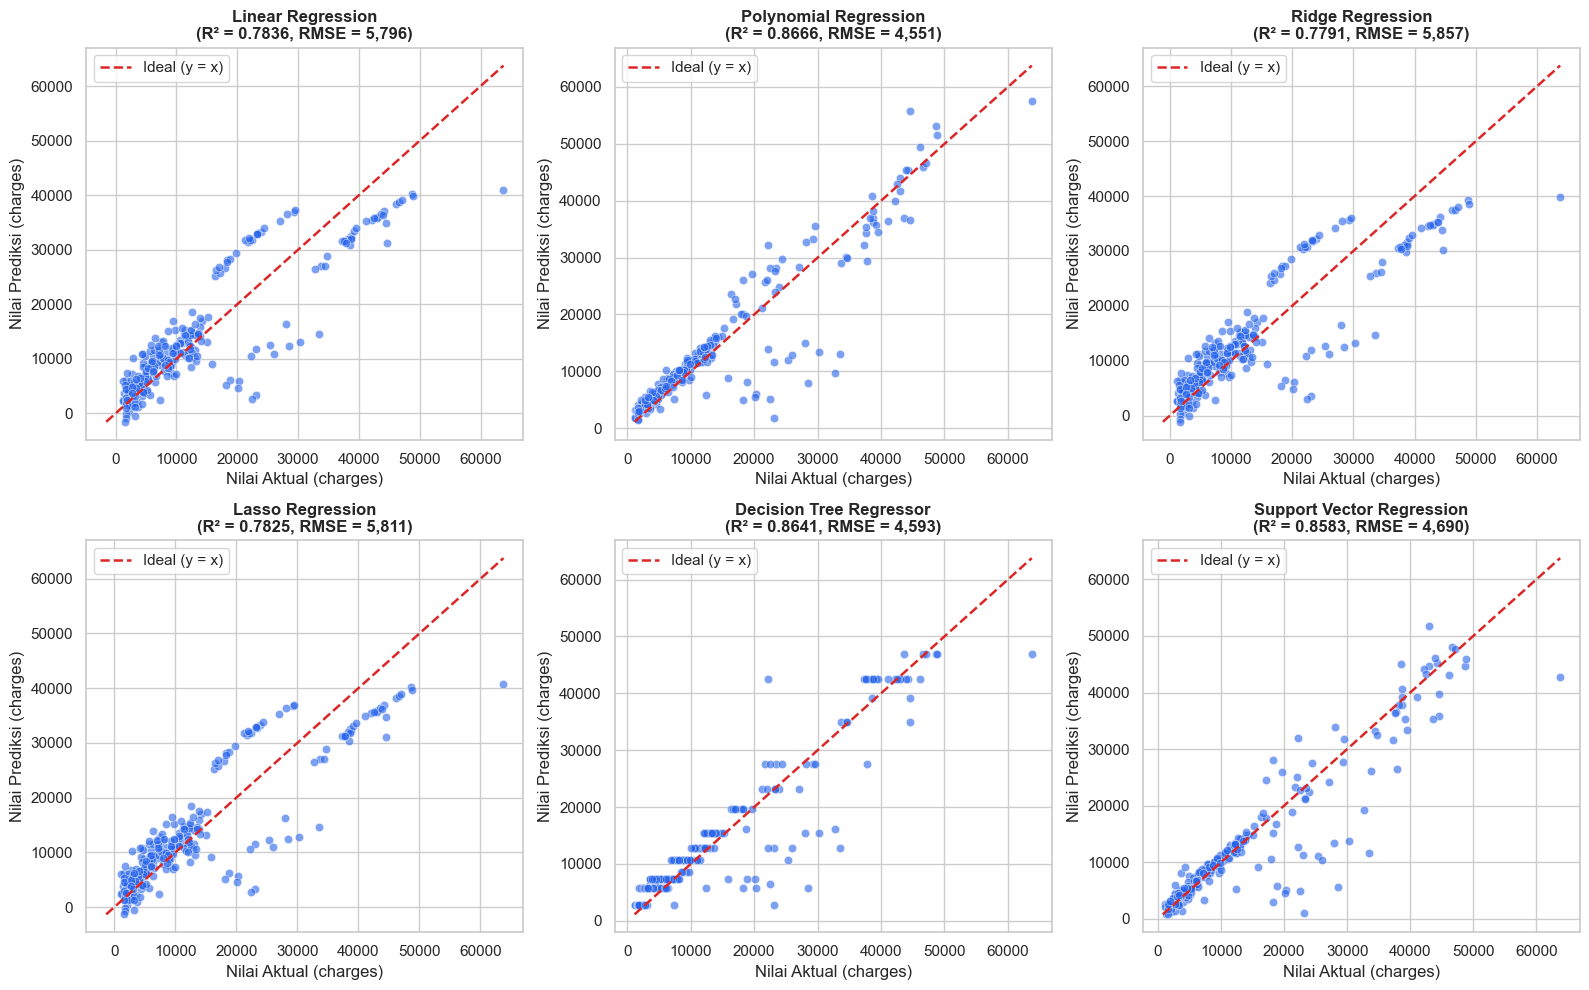

In [26]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, pred) in enumerate(models_dict.items()):
    ax = axes[i]
    sns.scatterplot(x=y_test, y=pred, alpha=0.6, color='#2563eb', ax=ax)
    
    # Garis ideal y = x
    min_v = min(y_test.min(), pred.min())
    max_v = max(y_test.max(), pred.max())
    ax.plot([min_v, max_v], [min_v, max_v], color='#dc2626', linestyle='--', linewidth=1.8, label='Ideal (y = x)')
    
    r2_val = r2_score(y_test, pred)
    rmse_val = np.sqrt(mean_squared_error(y_test, pred))
    ax.set_title(f"{name}\n(R² = {r2_val:.4f}, RMSE = {rmse_val:,.0f})", fontweight='bold')
    ax.set_xlabel('Nilai Aktual (charges)')
    ax.set_ylabel('Nilai Prediksi (charges)')
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.

### 1. Perbandingan Hasil Model Berdasarkan Metrik Evaluasi:
Berdasarkan metrik evaluasi pada data uji (MAE, MSE, RMSE, dan R²), keenam model terbagi menjadi dua kelompok performa:
- **Model Non-Linear (Performa Unggul):**
  1. **Polynomial Regression (degree=2):** Memperoleh R² tertinggi (**0.8666**) dan RMSE terendah (**4.551,13**).
  2. **Decision Tree Regressor (depth=4, leaf=10):** Memperoleh R² = **0.8641** dan RMSE = **4.592,76**, sangat kompetitif dan mudah diinterpretasikan.
  3. **Support Vector Regression (RBF, C=10.0):** Memperoleh R² = **0.8583** dan RMSE = **4.689,77**, serta mencatatkan **MAE terendah (2.379,54)**.
- **Model Linear Sederhana (Performa Terbatas):**
  - **Linear Regression, Ridge (alpha=10), dan Lasso (alpha=20):** Memiliki performa yang hampir identik dengan R² sekitar 0.779 - 0.784 dan RMSE sekitar 5.796 - 5.856. Model-model ini dibatasi oleh asumsi hubungan linear murni.

### 2. Mengapa Model Non-Linear Jauh Lebih Unggul?
Dataset biaya medis ini memiliki **interaksi non-linear yang sangat kuat**, terutama antara fitur status perokok (`smoker`) dan indeks massa tubuh (`bmi`):
- Pada kelompok non-perokok, kenaikan BMI hanya menyebabkan kenaikan biaya medis yang kecil.
- Namun pada perokok dengan BMI ≥ 30 (obesitas), biaya medis melonjak drastis ke kisaran 30.000 - 45.000+ USD.
- Model linear memaksakan bidang datar tunggal sehingga mengalami *underfitting* pada segmen perokok obesitas. Sebaliknya, Polynomial Regression membentuk suku interaksi silang (`bmi * smoker`), Decision Tree membagi aturan bertingkat (`smoker = yes` lalu `bmi > 30`), dan SVR RBF memetakan hubungan ke ruang dimensi tinggi melalui kernel RBF.

### 3. Pengaruh Preprocessing Data:
- **Feature Scaling (StandardScaler):** Sangat krusial untuk SVR (karena fungsi jarak Euclidean pada kernel RBF) dan model linear terregularisasi (Ridge/Lasso agar penalti koefisien adil). Sebaliknya, Decision Tree tidak terpengaruh oleh scaling karena pembagian cabang berbasis urutan/ranking nilai fitur (*monotonic invariant*).
- **Target Scaling pada SVR:** Nilai target `charges` bernilai ribuan hingga puluhan ribu. Penggunaan penskalaan target melalui `TransformedTargetRegressor` sangat penting agar margin epsilon dan parameter penalti C bawaan stabil dan konvergen cepat.

### 4. Pengaruh Parameter (Hyperparameter Tuning):
- **Degree pada Polynomial:** Degree 2 adalah titik optimal. Degree 1 underfitting (R² ~ 0.78), sedangkan degree 3 memicu lonjakan jumlah fitur yang berlebihan sehingga mengalami overfitting.
- **Alpha pada Ridge & Lasso:** Regularisasi alpha mencegah koefisien membesar secara liar. Pada Lasso, alpha moderat membantu menyusutkan koefisien fitur yang kurang informatif menjadi nol.
- **Max Depth & Min Samples Leaf pada Decision Tree:** Pohon tanpa batasan mengalami overfitting parah (menghafal data latih). Pembatasan `max_depth=4` dan `min_samples_leaf=10` memberikan regularisasi/pruning terbaik sehingga Test R² naik ke 0.8641.
- **Kernel & C pada SVR:** Kernel RBF jauh lebih unggul dibandingkan linear karena batas pemisah data non-linear. Parameter C=10.0 menyeimbangkan fleksibilitas kurva dan toleransi error.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.

### Kesimpulan:
1. **Model Terbaik:** **Polynomial Regression (degree=2)** menghasilkan akurasi tertinggi dengan R² = 0.8666 dan RMSE = 4.551,13, diikuti sangat ketat oleh **Decision Tree Regressor** (R² = 0.8641) dan **SVR RBF** (R² = 0.8583, MAE terendah).
2. **Karakteristik Data:** Pengaruh interaksi antara `smoker`, `bmi`, dan `age` bersifat non-linear, sehingga model non-linear mengungguli model linear sederhana dengan selisih performa sekitar 8.5%.
3. **Pentingnya Preprocessing:** Penskalaan fitur dan target sangat krusial bagi SVR dan regularisasi Ridge/Lasso, sedangkan Decision Tree dapat langsung menggunakan data tanpa scaling dengan hasil optimal.

---

### Saran untuk Eksperimen Lanjutan:
1. **Feature Engineering Interaksi Eksplisit:** Membuat variabel interaksi domain medis secara eksplisit, seperti variabel biner `obese_smoker = (bmi >= 30) & (smoker == 'yes')`, yang dapat meningkatkan akurasi model linear sekalipun.
2. **Transformasi Target Logaritmik:** Menerapkan transformasi logaritma `log(1 + charges)` pada target sebelum pemodelan untuk mengatasi kemiringan (*skewness*) distribusi biaya medis yang miring ke kanan.
3. **Mencoba Model Ensemble:** Mengembangkan model pohon ensemble seperti **Random Forest Regressor** atau **Gradient Boosting (XGBoost/LightGBM)** yang menggabungkan keunggulan ketahanan non-linear dengan varians prediksi yang lebih stabil.
4. **K-Fold Cross Validation:** Menerapkan 5-fold cross-validation dalam proses penentuan hyperparameter untuk menguji ketahanan model secara lebih komprehensif.